In [1]:
import numpy as np

class TrafficGenerator:
    def __init__(self, inflow_rate=0.5, av_ratio=0.1):
        # inflow_rate: 泊松分布的 lambda (例如 0.5 辆/秒)
        # av_ratio: 自动驾驶车辆的比例
        self.inflow_rate = inflow_rate
        self.av_ratio = av_ratio
        
    def spawn_vehicle(self, current_time):
        # 1. 泊松过程决定下一辆车的生成时间间隔
        dt_next = np.random.exponential(1.0 / self.inflow_rate)
        
        # 2. 掷骰子决定是 AV 还是 HV
        is_av = np.random.rand() < self.av_ratio
        
        # 3. 赋予不同的驾驶性格 (IDM 参数的高斯采样)
        if is_av:
            # AV 性格由 RL 控制，物理参数可以设定为最理想状态
            T, a = 1.0, 1.5 
        else:
            # HV 性格随机：有激进的 (T小, a大)，有保守的 (T大, a小)
            # 以 T=1.5秒为均值，0.3为标准差采样，限制在 [0.8, 2.5] 之间
            T = np.clip(np.random.normal(1.5, 0.3), 0.8, 2.5)
            a = np.clip(np.random.normal(1.0, 0.2), 0.5, 1.5)
            
        return {"time_to_spawn": current_time + dt_next, "is_av": is_av, "T": T, "a": a}

In [2]:
import matplotlib.pyplot as plt
import numpy as np

def plot_open_road_spacetime(trajectories, road_length=500):
    """
    trajectories: 字典列表，每个字典存储一辆车的历史记录
    [
      {"is_av": False, "times": [0, 0.5, 1.0...], "positions": [0, 5, 12...], "speeds": [...]},
      ...
    ]
    """
    fig, ax = plt.subplots(figsize=(12, 7))
    
    for veh in trajectories:
        times = np.array(veh["times"])
        positions = np.array(veh["positions"])
        speeds = np.array(veh["speeds"])
        
        # 过滤掉还未发车或已经驶出道路的数据
        mask = (positions >= 0) & (positions <= road_length)
        times, positions, speeds = times[mask], positions[mask], speeds[mask]
        
        if len(times) == 0: continue
            
        if veh["is_av"]:
            # AV 标为粗红线，突出其平滑作用和可能形成的编队
            ax.plot(times, positions, color='red', linewidth=2.5, zorder=5)
        else:
            # HV 使用速度上色 (冷暖色调)，直观显示哪里发生了刹车波
            sc = ax.scatter(times, positions, c=speeds, cmap='RdYlBu', s=3, vmin=0, vmax=15, zorder=3)

    plt.title(f"Open Straight Road Space-Time Diagram (AV Ratio: 10%)")
    plt.xlabel("Time (s)")
    plt.ylabel("Position (m) -> Exit at 500m")
    
    # 颜色条：深红代表堵车(0 m/s)，深蓝代表畅通(15 m/s)
    cbar = plt.colorbar(sc)
    cbar.set_label("Speed (m/s)")
    
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.xlim(0, max([max(v["times"]) for v in trajectories if len(v["times"])>0]))
    plt.ylim(0, road_length)
    plt.show()

In [3]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
from stable_baselines3 import PPO

class Vehicle:
    """内部辅助类：记录单辆车的物理状态和性格参数"""
    def __init__(self, x, v, is_av, is_ego, T, a):
        self.x = x              # 位置
        self.v = v              # 速度
        self.is_av = is_av      # 是否为自动驾驶车辆
        self.is_ego = is_ego    # 是否为当前受 RL 控制的“主角”
        self.T = T              # 安全时距 (性格)
        self.a = a              # 最大加速度 (性格)
        self.b = 1.5            # 舒适减速度
        self.s0 = 2.0           # 最小安全间距
        self.v0 = 15.0          # 期望速度 (约 54 km/h)

class OpenTrafficEnv(gym.Env):
    """
    单车道开放系统交通流环境 (Gymnasium API)
    用于训练单个 Ego AV 的连续跟驰策略
    """
    def __init__(self, road_length=500.0, dt=0.5, av_ratio=0.2):
        super(OpenTrafficEnv, self).__init__()
        self.road_length = road_length
        self.dt = dt
        self.av_ratio = av_ratio
        
        # 动作空间：连续加速度 [-3.0, 2.0]
        self.action_space = spaces.Box(low=-3.0, high=2.0, shape=(1,), dtype=np.float32)
        
        # 状态空间：5 维向量 [v_ego, s_lead, dv_lead, s_av, v_av]
        self.observation_space = spaces.Box(low=-100.0, high=self.road_length, shape=(5,), dtype=np.float32)
        
        self.vehicles = []
        self.time_to_next_spawn = 0.0
        self.step_count = 0
        self.max_steps = 1000  # 防止死循环的截断步数

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.vehicles = []
        self.step_count = 0
        
        # 预填充道路 (Pre-populate) 以免主角一开始在空路上跑
        # 在道路前方随机散布一些人类车辆
        for x in range(50, int(self.road_length - 50), 30):
            if np.random.rand() > 0.3: # 70%概率放置车辆
                v = np.random.normal(10.0, 2.0)
                T = np.clip(np.random.normal(1.5, 0.3), 0.8, 2.5)
                self.vehicles.append(Vehicle(x, v, is_av=False, is_ego=False, T=T, a=1.0))
                
        # 在道路起点 (x=0) 生成我们的“主角” Ego AV
        self.ego_veh = Vehicle(x=0.0, v=10.0, is_av=True, is_ego=True, T=1.0, a=1.5)
        self.vehicles.append(self.ego_veh)
        
        # 确保车辆按位置从远到近(降序)排序
        self.vehicles.sort(key=lambda v: v.x, reverse=True)
        self.time_to_next_spawn = np.random.exponential(2.0)
        
        return self._get_obs(), {}

    def _get_obs(self):
        # 初始化默认观测值 (前方无车的情况)
        v_ego = self.ego_veh.v
        s_lead, dv_lead = self.road_length, 0.0
        s_av, v_av = self.road_length, 15.0
        
        ego_idx = self.vehicles.index(self.ego_veh)
        
        # 寻找最近的前车
        if ego_idx > 0:
            lead_veh = self.vehicles[ego_idx - 1]
            s_lead = lead_veh.x - self.ego_veh.x
            dv_lead = self.ego_veh.v - lead_veh.v
            
            # 寻找前方最近的 V2V 联动车辆 (AV)
            for i in range(ego_idx - 1, -1, -1):
                if self.vehicles[i].is_av:
                    s_av = self.vehicles[i].x - self.ego_veh.x
                    v_av = self.vehicles[i].v
                    break

        return np.array([v_ego, s_lead, dv_lead, s_av, v_av], dtype=np.float32)

    def step(self, action):
        self.step_count += 1
        accelerations = []
        aeb_penalty = 0.0
        
        # 1. 泊松车流生成 (在起点 x=0 之后伺机生成新车)
        self.time_to_next_spawn -= self.dt
        if self.time_to_next_spawn <= 0:
            last_veh = self.vehicles[-1]
            # 如果起点有足够的空隙 (> 20米)，才生成新车
            if last_veh.x > 20.0:
                is_av = np.random.rand() < self.av_ratio
                T = 1.0 if is_av else np.clip(np.random.normal(1.5, 0.3), 0.8, 2.5)
                new_veh = Vehicle(x=0.0, v=15.0, is_av=is_av, is_ego=False, T=T, a=1.0)
                self.vehicles.append(new_veh)
                self.time_to_next_spawn = np.random.exponential(2.0)
        
        # 2. 计算所有车辆的加速度
        for i, veh in enumerate(self.vehicles):
            s = 999.0
            dv = 0.0
            if i > 0: # 前方有车
                lead_veh = self.vehicles[i - 1]
                s = lead_veh.x - veh.x
                dv = veh.v - lead_veh.v
                
            if veh.is_ego:
                # ==================================
                # 主角 (Ego AV) - 强化学习动作与 AEB 护盾
                # ==================================
                acc = action[0]
                critical_dist = 2.0 + veh.v * 0.8
                if s < critical_dist:
                    acc = -4.0
                    aeb_penalty = -5.0 # 触发安全护盾，重罚
            else:
                # ==================================
                # 其他车辆 (HV & 非主角AV) - IDM 模型
                # ==================================
                s_star = veh.s0 + veh.v * veh.T + (veh.v * dv) / (2 * np.sqrt(veh.a * veh.b))
                s_star = max(s_star, veh.s0)
                acc = veh.a * (1 - (veh.v / veh.v0)**4 - (s_star / max(s, 0.1))**2)
                
                # 物理防穿模
                if s < veh.s0:
                    acc = -4.0
                acc = np.clip(acc, -4.0, 2.0)
                
            accelerations.append(acc)
            
        # 3. 更新物理状态
        for i, veh in enumerate(self.vehicles):
            veh.v += accelerations[i] * self.dt
            veh.v = np.clip(veh.v, 0.0, veh.v0) # 防止倒车，限制极速
            veh.x += veh.v * self.dt
            
        # 4. 清理驶出道路的车辆，并更新排序
        self.vehicles = [v for v in self.vehicles if v.x < self.road_length]
        self.vehicles.sort(key=lambda v: v.x, reverse=True)
        
        # 5. 判断结束条件 (Terminated/Truncated)
        terminated = False
        # 如果 Ego AV 成功驶离道路，结束回合
        if self.ego_veh not in self.vehicles:
            terminated = True
            
        truncated = self.step_count >= self.max_steps
        
        # 6. 计算局部平滑奖励 (Reward)
        reward = 0.0
        if not terminated:
            # 找到 Ego 前后 50 米内的所有车辆，计算它们的平均速度
            local_vehicles = [v for v in self.vehicles if abs(v.x - self.ego_veh.x) <= 50.0]
            local_avg_v = np.mean([v.v for v in local_vehicles])
            
            # Reward = 0.4 * 自身效率 + 0.6 * 局部平滑度 - AEB惩罚
            reward = 0.4 * (self.ego_veh.v / 15.0) + 0.6 * (local_avg_v / 15.0) + aeb_penalty
        else:
            # 成功抵达终点给一笔大奖
            reward += 20.0 

        # SB3 的新 API 要求返回 5 个值
        return self._get_obs() if not terminated else np.zeros(5, dtype=np.float32), reward, terminated, truncated, {}

# ==========================================
# 训练与测试启动脚本
# ==========================================
if __name__ == "__main__":
    env = OpenTrafficEnv()
    
    print("开始训练 PPO 模型，预计需要 30 秒 - 1 分钟...")
    model = PPO("MlpPolicy", env, verbose=1, learning_rate=3e-4)
    # 训练 20,000 步作为初始验证 (期末跑数据建议 100,000 步起)
    model.learn(total_timesteps=20000)
    print("模型训练完成！")
    
    # 保存模型以便 Deliverable 使用
    model.save("ppo_av_platooning")
    
    print("测试一轮模型...")
    obs, info = env.reset()
    total_reward = 0
    while True:
        action, _states = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        if terminated or truncated:
            break
            
    print(f"单轮测试总奖励: {total_reward:.2f}")

开始训练 PPO 模型，预计需要 30 秒 - 1 分钟...
Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | 87.2     |
| time/              |          |
|    fps             | 2255     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 99.6        |
|    ep_rew_mean          | 86.2        |
| time/                   |             |
|    fps                  | 1574        |
|    iterations           | 2           |
|    time_elapsed         | 2           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.007854607 |
|    clip_fraction        | 0.0983      |
|    clip_range           | 0.

加载训练好的 RL 大脑...
开始多智能体物理仿真...
仿真结束，正在渲染时空图...


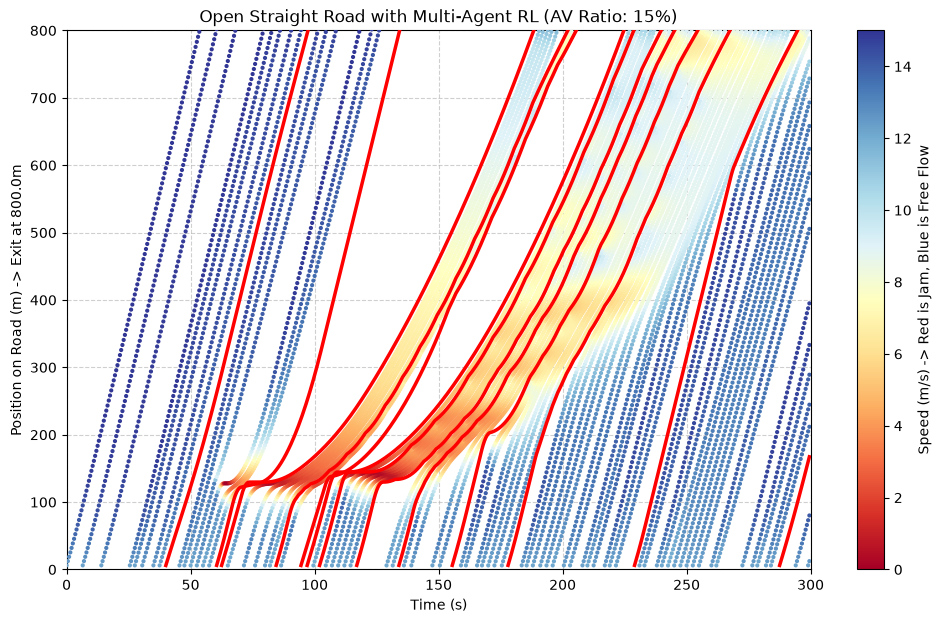

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import PPO

# ==========================================
# 1. 定义物理车辆与状态提取逻辑
# ==========================================
class Vehicle:
    def __init__(self, id, x, v, is_av, T, a):
        self.id = id            # 车辆唯一标识
        self.x = x              # 位置
        self.v = v              # 速度
        self.is_av = is_av      # 是否为自动驾驶
        self.T = T              # 安全时距
        self.a = a              # 最大加速度
        self.b = 1.5
        self.s0 = 2.0
        self.v0 = 15.0
        # 记录轨迹用于画图
        self.history_t = []
        self.history_x = []
        self.history_v = []

def get_av_obs(veh, all_vehicles, road_length):
    """为某一辆具体的 AV 提取 5 维观测状态"""
    v_ego = veh.v
    s_lead, dv_lead = road_length, 0.0
    s_av, v_av = road_length, 15.0
    
    idx = all_vehicles.index(veh)
    if idx > 0:
        lead_veh = all_vehicles[idx - 1]
        s_lead = lead_veh.x - veh.x
        dv_lead = veh.v - lead_veh.v
        
        # 向前寻找最近的另一辆 AV (用于 V2V 联动)
        for i in range(idx - 1, -1, -1):
            if all_vehicles[i].is_av:
                s_av = all_vehicles[i].x - veh.x
                v_av = all_vehicles[i].v
                break
                
    return np.array([v_ego, s_lead, dv_lead, s_av, v_av], dtype=np.float32)

# ==========================================
# 2. 多智能体仿真循环 (The Cloning Execution)
# ==========================================
print("加载训练好的 RL 大脑...")
model = PPO.load("ppo_av_platooning")

road_length = 800.0
dt = 0.5
steps = 600  # 模拟 300 秒
av_ratio = 0.15 # 设定 15% 的车辆为 AV

vehicles = []
finished_vehicles = [] # 记录已驶出道路的车辆数据
veh_counter = 0
time_to_spawn = 0.0

print("开始多智能体物理仿真...")
for t in range(steps):
    current_time = t * dt
    
    # 1. 泊松车流生成 (起点有空隙时)
    time_to_spawn -= dt
    if time_to_spawn <= 0 and (len(vehicles) == 0 or vehicles[-1].x > 25.0):
        is_av = np.random.rand() < av_ratio
        T = 1.0 if is_av else np.clip(np.random.normal(1.5, 0.3), 0.8, 2.5)
        new_veh = Vehicle(id=veh_counter, x=0.0, v=12.0, is_av=is_av, T=T, a=1.0)
        vehicles.append(new_veh)
        veh_counter += 1
        time_to_spawn = np.random.exponential(2.5) # 平均每 2.5 秒来一辆车
        
    accelerations = []
    
    # 2. 为所有车辆计算加速度
    for i, veh in enumerate(vehicles):
        s, dv = 999.0, 0.0
        if i > 0:
            lead_veh = vehicles[i - 1]
            s = lead_veh.x - veh.x
            dv = veh.v - lead_veh.v
            
        critical_dist = 2.0 + veh.v * 0.8
        
        if veh.is_av:
            # 【克隆核心】所有 AV 都调用同一个 model.predict 
            obs = get_av_obs(veh, vehicles, road_length)
            action, _ = model.predict(obs, deterministic=True)
            acc = action[0]
            
            # AEB 兜底
            if s < critical_dist: acc = -4.0
        else:
            # HV 使用 IDM 计算
            s_star = veh.s0 + veh.v * veh.T + (veh.v * dv) / (2 * np.sqrt(veh.a * veh.b))
            s_star = max(s_star, veh.s0)
            acc = veh.a * (1 - (veh.v / veh.v0)**4 - (s_star / max(s, 0.1))**2)
            if s < veh.s0: acc = -4.0
            acc = np.clip(acc, -4.0, 2.0)
            
        # 【制造交通拥堵】第 60 秒时，最前面的一辆车突然急刹车，制造冲击波
        if 120 <= t <= 130 and i == 10:
            acc = -4.0          # 踩死刹车
            #veh.v = 0.1         # 强制把速度压到近乎 0 (不能完全为0以防公式除零报错)    
        accelerations.append(acc)
        
    # 3. 物理更新与记录数据
    for i, veh in enumerate(vehicles):
        veh.v = np.clip(veh.v + accelerations[i] * dt, 0.0, veh.v0)
        veh.x += veh.v * dt
        veh.history_t.append(current_time)
        veh.history_x.append(veh.x)
        veh.history_v.append(veh.v)
        
    # 4. 移除驶出道路的车辆
    surviving_vehicles = []
    for veh in vehicles:
        if veh.x >= road_length:
            finished_vehicles.append(veh)
        else:
            surviving_vehicles.append(veh)
    vehicles = surviving_vehicles

finished_vehicles.extend(vehicles) # 把还在路上的也加进去一起画图

# ==========================================
# 3. 生成时空轨迹图 (Space-Time Diagram)
# ==========================================
print("仿真结束，正在渲染时空图...")
fig, ax = plt.subplots(figsize=(12, 7))

for veh in finished_vehicles:
    if len(veh.history_t) == 0: continue
    
    if veh.is_av:
        # AV 轨迹画为粗红线
        ax.plot(veh.history_t, veh.history_x, color='red', linewidth=2.5, zorder=5)
    else:
        # HV 轨迹用速度上色
        sc = ax.scatter(veh.history_t, veh.history_x, c=veh.history_v, 
                        cmap='RdYlBu', s=4, vmin=0, vmax=15, zorder=3)

plt.title(f"Open Straight Road with Multi-Agent RL (AV Ratio: {av_ratio*100:.0f}%)")
plt.xlabel("Time (s)")
plt.ylabel(f"Position on Road (m) -> Exit at {road_length}m")
cbar = plt.colorbar(sc)
cbar.set_label("Speed (m/s) -> Red is Jam, Blue is Free Flow")
plt.xlim(0, steps * dt)
plt.ylim(0, road_length)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display

# 1. 预处理数据以保证动画播放极其流畅
# 我们需要把每辆车的数据按“帧(时间步)”重新组织
frame_data = {t: {'x': [], 'color': []} for t in range(steps)}

for veh in finished_vehicles:
    color = 'red' if veh.is_av else 'black'
    for t_val, x_val in zip(veh.history_t, veh.history_x):
        # 计算当前时间对应的帧索引
        frame_idx = int(round(t_val / dt))
        if frame_idx < steps:
            frame_data[frame_idx]['x'].append(x_val)
            frame_data[frame_idx]['color'].append(color)

# 2. 初始化直道动画画布
fig, ax = plt.subplots(figsize=(15, 2)) # 宽长条形，模拟直道
ax.set_xlim(0, road_length)
ax.set_ylim(-0.5, 0.5)
ax.axis('off') 
ax.set_title("Open Single-Lane Traffic Simulation\n(Red: Autonomous Vehicle, Black: Human Driver)")

# 画出灰色的柏油马路
ax.axhline(0, color='gray', linewidth=40, alpha=0.3, zorder=1)
# 画出起点和终点线
ax.axvline(0, color='green', linestyle='--', linewidth=2, zorder=2)
ax.axvline(road_length, color='red', linestyle='--', linewidth=2, zorder=2)

# 初始化散点
scat = ax.scatter([], [], s=100, zorder=3)

def init():
    scat.set_offsets(np.empty((0, 2)))
    return scat,

def update(frame):
    x_coords = frame_data[frame]['x']
    colors = frame_data[frame]['color']
    
    if len(x_coords) > 0:
        # y坐标全部设为 0，因为是单车道
        data = np.c_[x_coords, np.zeros_like(x_coords)]
        scat.set_offsets(data)
        scat.set_color(colors)
    else:
        scat.set_offsets(np.empty((0, 2)))
        
    return scat,

# 生成动画 (每帧 50 毫秒)
ani = animation.FuncAnimation(
    fig, update, frames=steps,
    init_func=init, interval=50, blit=True
)

plt.close(fig)

# 3. 在 Jupyter 中渲染为带播放器的 HTML 组件
display(HTML(ani.to_jshtml()))

Where no AV is present:

加载训练好的 RL 大脑...
开始多智能体物理仿真...
仿真结束，正在渲染时空图...


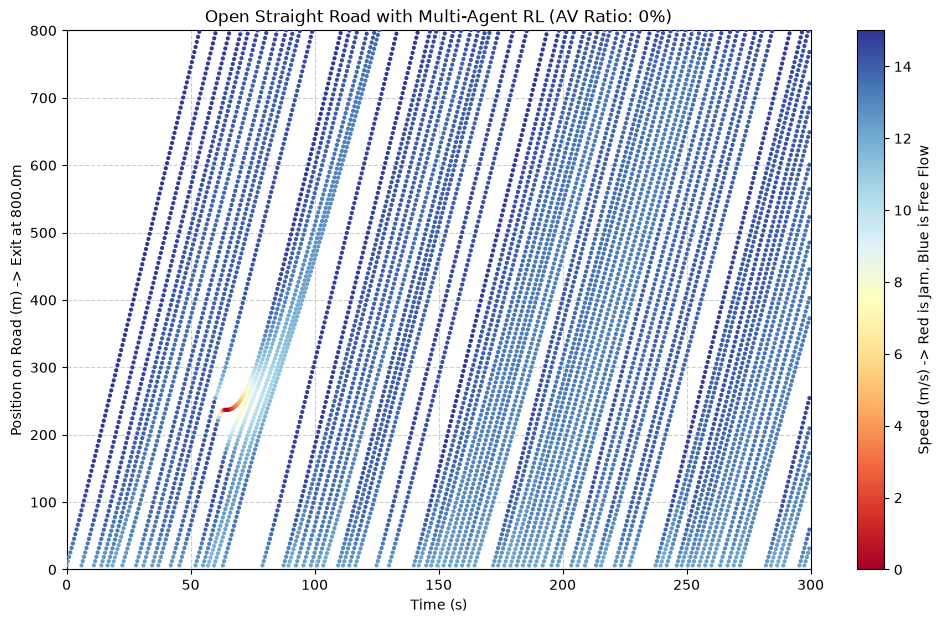

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import PPO

# ==========================================
# 1. 定义物理车辆与状态提取逻辑
# ==========================================
class Vehicle:
    def __init__(self, id, x, v, is_av, T, a):
        self.id = id            # 车辆唯一标识
        self.x = x              # 位置
        self.v = v              # 速度
        self.is_av = is_av      # 是否为自动驾驶
        self.T = T              # 安全时距
        self.a = a              # 最大加速度
        self.b = 1.5
        self.s0 = 2.0
        self.v0 = 15.0
        # 记录轨迹用于画图
        self.history_t = []
        self.history_x = []
        self.history_v = []

def get_av_obs(veh, all_vehicles, road_length):
    """为某一辆具体的 AV 提取 5 维观测状态"""
    v_ego = veh.v
    s_lead, dv_lead = road_length, 0.0
    s_av, v_av = road_length, 15.0
    
    idx = all_vehicles.index(veh)
    if idx > 0:
        lead_veh = all_vehicles[idx - 1]
        s_lead = lead_veh.x - veh.x
        dv_lead = veh.v - lead_veh.v
        
        # 向前寻找最近的另一辆 AV (用于 V2V 联动)
        for i in range(idx - 1, -1, -1):
            if all_vehicles[i].is_av:
                s_av = all_vehicles[i].x - veh.x
                v_av = all_vehicles[i].v
                break
                
    return np.array([v_ego, s_lead, dv_lead, s_av, v_av], dtype=np.float32)

# ==========================================
# 2. 多智能体仿真循环 (The Cloning Execution)
# ==========================================
print("加载训练好的 RL 大脑...")
model = PPO.load("ppo_av_platooning")

road_length = 800.0
dt = 0.5
steps = 600  # 模拟 300 秒
av_ratio = 0.0 # 设定 15% 的车辆为 AV

vehicles = []
finished_vehicles = [] # 记录已驶出道路的车辆数据
veh_counter = 0
time_to_spawn = 0.0

print("开始多智能体物理仿真...")
for t in range(steps):
    current_time = t * dt
    
    # 1. 泊松车流生成 (起点有空隙时)
    time_to_spawn -= dt
    if time_to_spawn <= 0 and (len(vehicles) == 0 or vehicles[-1].x > 25.0):
        is_av = np.random.rand() < av_ratio
        T = 1.0 if is_av else np.clip(np.random.normal(1.5, 0.3), 0.8, 2.5)
        new_veh = Vehicle(id=veh_counter, x=0.0, v=12.0, is_av=is_av, T=T, a=1.0)
        vehicles.append(new_veh)
        veh_counter += 1
        time_to_spawn = np.random.exponential(2.5) # 平均每 2.5 秒来一辆车
        
    accelerations = []
    
    # 2. 为所有车辆计算加速度
    for i, veh in enumerate(vehicles):
        s, dv = 999.0, 0.0
        if i > 0:
            lead_veh = vehicles[i - 1]
            s = lead_veh.x - veh.x
            dv = veh.v - lead_veh.v
            
        critical_dist = 2.0 + veh.v * 0.8
        
        if veh.is_av:
            # 【克隆核心】所有 AV 都调用同一个 model.predict 
            obs = get_av_obs(veh, vehicles, road_length)
            action, _ = model.predict(obs, deterministic=True)
            acc = action[0]
            
            # AEB 兜底
            if s < critical_dist: acc = -4.0
        else:
            # HV 使用 IDM 计算
            s_star = veh.s0 + veh.v * veh.T + (veh.v * dv) / (2 * np.sqrt(veh.a * veh.b))
            s_star = max(s_star, veh.s0)
            acc = veh.a * (1 - (veh.v / veh.v0)**4 - (s_star / max(s, 0.1))**2)
            if s < veh.s0: acc = -4.0
            acc = np.clip(acc, -4.0, 2.0)
            
        # 【制造交通拥堵】第 60 秒时，最前面的一辆车突然急刹车，制造冲击波
        if 120 <= t <= 130 and i == 10:
            acc = -4.0          # 踩死刹车
            #veh.v = 0.1         # 强制把速度压到近乎 0 (不能完全为0以防公式除零报错)    
        accelerations.append(acc)
        
    # 3. 物理更新与记录数据
    for i, veh in enumerate(vehicles):
        veh.v = np.clip(veh.v + accelerations[i] * dt, 0.0, veh.v0)
        veh.x += veh.v * dt
        veh.history_t.append(current_time)
        veh.history_x.append(veh.x)
        veh.history_v.append(veh.v)
        
    # 4. 移除驶出道路的车辆
    surviving_vehicles = []
    for veh in vehicles:
        if veh.x >= road_length:
            finished_vehicles.append(veh)
        else:
            surviving_vehicles.append(veh)
    vehicles = surviving_vehicles

finished_vehicles.extend(vehicles) # 把还在路上的也加进去一起画图

# ==========================================
# 3. 生成时空轨迹图 (Space-Time Diagram)
# ==========================================
print("仿真结束，正在渲染时空图...")
fig, ax = plt.subplots(figsize=(12, 7))

for veh in finished_vehicles:
    if len(veh.history_t) == 0: continue
    
    if veh.is_av:
        # AV 轨迹画为粗红线
        ax.plot(veh.history_t, veh.history_x, color='red', linewidth=2.5, zorder=5)
    else:
        # HV 轨迹用速度上色
        sc = ax.scatter(veh.history_t, veh.history_x, c=veh.history_v, 
                        cmap='RdYlBu', s=4, vmin=0, vmax=15, zorder=3)

plt.title(f"Open Straight Road with Multi-Agent RL (AV Ratio: {av_ratio*100:.0f}%)")
plt.xlabel("Time (s)")
plt.ylabel(f"Position on Road (m) -> Exit at {road_length}m")
cbar = plt.colorbar(sc)
cbar.set_label("Speed (m/s) -> Red is Jam, Blue is Free Flow")
plt.xlim(0, steps * dt)
plt.ylim(0, road_length)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()